In [1]:
#câu 1:
import numpy as np
from sklearn.svm import SVC

# 24 điểm minh họa: 12 điểm lớp 0 và 12 điểm lớp 1.
# Thay X, y bằng đúng 24 điểm ở mục 2 nếu đề/bài giảng cung cấp bộ dữ liệu khác.
X0 = np.array([
    [0.0, 0.0], [0.5, 0.2], [1.0, 0.1], [1.5, 0.4],
    [2.0, 0.2], [2.5, 0.6], [3.0, 0.5], [3.5, 0.8],
    [4.0, 0.7], [4.5, 1.0], [5.0, 0.9], [5.5, 1.2]
])
X1 = np.array([
    [0.0, 3.0], [0.5, 3.2], [1.0, 3.1], [1.5, 3.4],
    [2.0, 3.2], [2.5, 3.6], [3.0, 3.5], [3.5, 3.8],
    [4.0, 3.7], [4.5, 4.0], [5.0, 3.9], [5.5, 4.2]
])
X = np.vstack([X0, X1])
y = np.array([0]*len(X0) + [1]*len(X1))

model = SVC(kernel="linear", C=1e6)
model.fit(X, y)

w = model.coef_[0]
b = model.intercept_[0]
print(f"w1 = {w[0]:.6f}")
print(f"w2 = {w[1]:.6f}")
print(f"b  = {b:.6f}")
print("Số support vector:", len(model.support_vectors_))
print("Support vectors:\n", model.support_vectors_)

# Hai điểm đề bài yêu cầu
points = np.array([[3.0, 3.0], [5.0, 4.5]])
names = ["(3, 3)", "(5, 4.5)"]

norm_w = np.sqrt(w[0]**2 + w[1]**2)
for name, (x1, x2) in zip(names, points):
    # Tính trực tiếp bằng phép nhân và cộng, không dùng decision_function
    f_x = w[0]*x1 + w[1]*x2 + b
    distance = abs(f_x) / norm_w
    print(f"Điểm {name}: f(x) = ({w[0]:.6f}*{x1}) + "
          f"({w[1]:.6f}*{x2}) + ({b:.6f}) = {f_x:.6f}")
    print(f"          Khoảng cách = |{f_x:.6f}|/{norm_w:.6f} = {distance:.6f}\n")

# Khoảng cách của từng support vector đến siêu phẳng phân chia
sv = model.support_vectors_
sv_f = sv @ w + b
sv_dist = np.abs(sv_f) / norm_w
print("Khoảng cách các support vector:")
for p, fx, d in zip(sv, sv_f, sv_dist):
    print(f"{p} -> f(x)={fx:.6f}, khoảng cách={d:.6f}")

margin_half = 1 / norm_w
margin_width = 2 / norm_w
print(f"\n1/||w|| (nửa độ rộng lề) = {margin_half:.6f}")
print(f"2/||w|| (độ rộng lề)     = {margin_width:.6f}")

w1 = -0.148204
w2 = 0.741020
b  = -1.074353
Số support vector: 3
Support vectors:
 [[0.5 0.2]
 [5.5 1.2]
 [2.  3.2]]
Điểm (3, 3): f(x) = (-0.148204*3.0) + (0.741020*3.0) + (-1.074353) = 0.704095
          Khoảng cách = |0.704095|/0.755695 = 0.931718

Điểm (5, 4.5): f(x) = (-0.148204*5.0) + (0.741020*4.5) + (-1.074353) = 1.519217
          Khoảng cách = |1.519217|/0.755695 = 2.010357

Khoảng cách các support vector:
[0.5 0.2] -> f(x)=-1.000251, khoảng cách=1.323618
[5.5 1.2] -> f(x)=-1.000251, khoảng cách=1.323617
[2.  3.2] -> f(x)=1.000503, khoảng cách=1.323950

1/||w|| (nửa độ rộng lề) = 1.323285
2/||w|| (độ rộng lề)     = 2.646570


Với SVM tuyến tính dạng chuẩn, các support vector nằm trên hai đường biên lề thỏa mãn (y_i(w^Tx_i+b)=1). Vì vậy (|f(x_i)|=1), nên khoảng cách từ mỗi support vector đến đường ranh giới (w^Tx+b=0) bằng (1/|w|).

Đây là nửa độ rộng lề. Khoảng cách giữa hai đường biên lề (w^Tx+b=1) và (w^Tx+b=-1) là (2/|w|). Nếu dùng SVM với C hữu hạn hoặc dữ liệu không phân tách hoàn hảo, một số support vector có thể nằm trong lề; khi đó khoảng cách không nhất thiết đúng bằng (1/|w|).

Mô hình ban đầu
w1=-0.148204, w2=0.741020, b=-1.074353
Support vectors: [[0.5 0.2]
 [5.5 1.2]
 [2.  3.2]]
Sau khi thêm điểm lớp 1 tại (-1, -1)
w1=-0.439102, w2=1.057935, b=-1.000167
Support vectors: [[ 0.   0. ]
 [ 0.5  0.2]
 [ 4.5  4. ]
 [ 5.   3.9]
 [-1.  -1. ]]
Sau khi thêm điểm lớp 1 tại (4.5, 4)
w1=-0.148204, w2=0.741020, b=-1.074353
Support vectors: [[0.5 0.2]
 [5.5 1.2]
 [2.  3.2]]
So sánh ban đầu và trường hợp A
w ban đầu: [-0.14820402  0.74102011] b: -1.0743534196125448
w mới:     [-0.43910211  1.05793511] b: -1.0001672447050638
w có đổi không? True
b có đổi không? True

So sánh ban đầu và trường hợp B
w ban đầu: [-0.14820402  0.74102011] b: -1.0743534196125448
w mới:     [-0.14820402  0.74102011] b: -1.0743534196125448
w có đổi không? False
b có đổi không? False


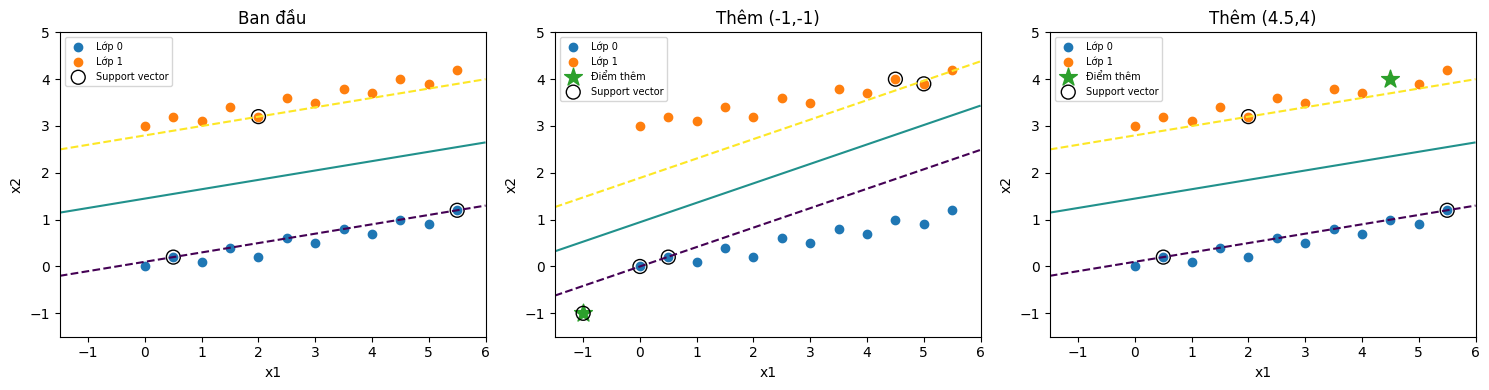

In [2]:
#câu 2:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

X0 = np.array([
    [0.0, 0.0], [0.5, 0.2], [1.0, 0.1], [1.5, 0.4],
    [2.0, 0.2], [2.5, 0.6], [3.0, 0.5], [3.5, 0.8],
    [4.0, 0.7], [4.5, 1.0], [5.0, 0.9], [5.5, 1.2]
])
X1 = np.array([
    [0.0, 3.0], [0.5, 3.2], [1.0, 3.1], [1.5, 3.4],
    [2.0, 3.2], [2.5, 3.6], [3.0, 3.5], [3.5, 3.8],
    [4.0, 3.7], [4.5, 4.0], [5.0, 3.9], [5.5, 4.2]
])
X = np.vstack([X0, X1])
y = np.array([0]*12 + [1]*12)

def fit_and_report(X_train, y_train, title):
    clf = SVC(kernel="linear", C=1e6)
    clf.fit(X_train, y_train)
    print(title)
    print(f"w1={clf.coef_[0,0]:.6f}, w2={clf.coef_[0,1]:.6f}, "
          f"b={clf.intercept_[0]:.6f}")
    print("Support vectors:", clf.support_vectors_)
    return clf

base = fit_and_report(X, y, "Mô hình ban đầu")
# Trường hợp A: thêm điểm lớp 1 tại (-1, -1)
XA = np.vstack([X, [-1.0, -1.0]])
yA = np.append(y, 1)
model_A = fit_and_report(XA, yA, "Sau khi thêm điểm lớp 1 tại (-1, -1)")
# Trường hợp B: bỏ điểm (-1,-1), thay bằng điểm lớp 1 tại (4.5, 4)
XB = np.vstack([X, [4.5, 4.0]])
yB = np.append(y, 1)
model_B = fit_and_report(XB, yB, "Sau khi thêm điểm lớp 1 tại (4.5, 4)")
def compare_models(m1, m2, label):
    print(label)
    print("w ban đầu:", m1.coef_[0], "b:", m1.intercept_[0])
    print("w mới:    ", m2.coef_[0], "b:", m2.intercept_[0])
    print("w có đổi không?", not np.allclose(m1.coef_[0], m2.coef_[0]))
    print("b có đổi không?", not np.allclose(m1.intercept_[0], m2.intercept_[0]))

compare_models(base, model_A, "So sánh ban đầu và trường hợp A")
print()
compare_models(base, model_B, "So sánh ban đầu và trường hợp B")
# Vẽ trực quan ba mô hình trên cùng mặt phẳng
xx = np.linspace(-1.5, 6, 250)
yy = np.linspace(-1.5, 5, 250)
XX, YY = np.meshgrid(xx, yy)
grid = np.c_[XX.ravel(), YY.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, clf, title, extra in [
    (axes[0], base, "Ban đầu", None),
    (axes[1], model_A, "Thêm (-1,-1)", [-1, -1]),
    (axes[2], model_B, "Thêm (4.5,4)", [4.5, 4])
]:
    ax.scatter(X0[:,0], X0[:,1], label="Lớp 0")
    ax.scatter(X1[:,0], X1[:,1], label="Lớp 1")
    if extra is not None:
        ax.scatter(*extra, marker="*", s=180, label="Điểm thêm")
    Z = clf.decision_function(grid).reshape(XX.shape)
    ax.contour(XX, YY, Z, levels=[-1, 0, 1],
               linestyles=["--", "-", "--"])
    ax.scatter(clf.support_vectors_[:,0], clf.support_vectors_[:,1],
               s=100, facecolors="none", edgecolors="black",
               label="Support vector")
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

Nhận xét
SVM chỉ phụ thuộc trực tiếp vào các điểm quyết định vị trí lề, gọi là support vectors. Nếu điểm mới nằm xa vùng biên và không trở thành support vector, đường ranh giới thường không đổi. Nếu điểm mới nằm gần biên, nằm trong lề hoặc làm thay đổi tập support vector, nghiệm tối ưu có thể thay đổi.

Hãy căn cứ vào ba bộ giá trị w1, w2, b được in ra và hình vẽ để kết luận trường hợp nào thay đổi. Bộ 24 điểm trong notebook là dữ liệu minh họa; với dữ liệu gốc của mục 2, kết quả có thể khác.

In [3]:
#câu 3:
import numpy as np
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
best_models = {}

for degree in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly"))
    search = GridSearchCV(
        pipe,
        param_grid={"svc__C": [0.1, 1, 10, 100]},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    search.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, search.predict(X_test))
    best_models[degree] = search.best_estimator_
    results.append({
        "degree": degree,
        "C tốt nhất": search.best_params_["svc__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": test_acc
    })

poly_results = pd.DataFrame(results).sort_values("CV accuracy", ascending=False)
display(poly_results)
# Mốc so sánh RBF: cùng dữ liệu, cùng cách chia và cùng CV
rbf_pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
rbf_search = GridSearchCV(
    rbf_pipe,
    param_grid={"svc__C": [0.1, 1, 10, 100],
                "svc__gamma": [0.01, 0.1, 1, 10]},
    cv=cv, scoring="accuracy", n_jobs=-1
)
rbf_search.fit(X_train, y_train)
rbf_test = accuracy_score(y_test, rbf_search.predict(X_test))
print("RBF best params:", rbf_search.best_params_)
print(f"RBF CV accuracy: {rbf_search.best_score_:.4f}")
print(f"RBF test accuracy: {rbf_test:.4f}")

best_poly = poly_results.iloc[0]
print("\nBậc đa thức tốt nhất:", int(best_poly["degree"]))
print(f"CV accuracy tốt nhất của poly: {best_poly['CV accuracy']:.4f}")
print("Poly có vượt RBF theo CV không?",
      best_poly["CV accuracy"] > rbf_search.best_score_)

,degree,C tốt nhất,CV accuracy,Test accuracy
0,2,0.1,0.84,0.816
1,3,0.1,0.84,0.816
2,4,0.1,0.84,0.816


RBF best params: {'svc__C': 1, 'svc__gamma': 1}
RBF CV accuracy: 0.9253
RBF test accuracy: 0.9120

Bậc đa thức tốt nhất: 2
CV accuracy tốt nhất của poly: 0.8400
Poly có vượt RBF theo CV không? False


Nhận xét
Bảng kết quả cho biết bậc đa thức và C nào có accuracy kiểm định chéo cao nhất. So sánh công bằng với RBF cần dùng cùng dữ liệu, cách chia train/test và chiến lược cross-validation.

Kernel đa thức có thể mô tả một số ranh giới phi tuyến, nhưng không phải lúc nào cũng phù hợp với hình dạng hai vầng trăng. RBF thường linh hoạt hơn vì gamma điều khiển phạm vi ảnh hưởng của từng điểm. Kết luận bậc nào tốt nhất phải dựa trên bảng kết quả thực tế được chạy trong notebook.

In [4]:
#câu 4:
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=500, noise=0.30, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
param_grid = {
    "svc__C": [3, 10, 30],
    "svc__gamma": [0.3, 1, 3]
}
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy",
                      n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
results = pd.DataFrame(search.cv_results_)[
    ["param_svc__C", "param_svc__gamma", "mean_test_score",
     "std_test_score", "mean_train_score", "rank_test_score"]
].sort_values("rank_test_score")
display(results)

best_model = search.best_estimator_
test_accuracy = accuracy_score(y_test, best_model.predict(X_test))
print("Tham số tốt nhất:", search.best_params_)
print(f"CV accuracy tốt nhất: {search.best_score_:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

# Mốc 0.8711 được đề bài nêu ở mục 5
print("CV có cao hơn 0.8711 không?", search.best_score_ > 0.8711)
results = pd.DataFrame(search.cv_results_)[
    ["param_svc__C", "param_svc__gamma", "mean_test_score",
     "std_test_score", "mean_train_score", "rank_test_score"]
].sort_values("rank_test_score")
display(results)

best_model = search.best_estimator_
test_accuracy = accuracy_score(y_test, best_model.predict(X_test))
print("Tham số tốt nhất:", search.best_params_)
print(f"CV accuracy tốt nhất: {search.best_score_:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

# Mốc 0.8711 được đề bài nêu ở mục 5
print("CV có cao hơn 0.8711 không?", search.best_score_ > 0.8711)

,param_svc__C,param_svc__gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
1,3,1.0,0.930667,0.034150,0.935333,1
6,30,0.3,0.928000,0.038274,0.936000,2
4,10,1.0,0.920000,0.030405,0.938667,3
7,30,1.0,0.917333,0.028472,0.938000,4
5,10,3.0,0.917333,0.027195,0.942667,5
2,3,3.0,0.914667,0.031098,0.940667,6
3,10,0.3,0.909333,0.048735,0.928667,7
8,30,3.0,0.904000,0.035176,0.946000,8
0,3,0.3,0.901333,0.052392,0.912667,9


Tham số tốt nhất: {'svc__C': 3, 'svc__gamma': 1}
CV accuracy tốt nhất: 0.9307
Test accuracy: 0.9120
CV có cao hơn 0.8711 không? True


,param_svc__C,param_svc__gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
1,3,1.0,0.930667,0.034150,0.935333,1
6,30,0.3,0.928000,0.038274,0.936000,2
4,10,1.0,0.920000,0.030405,0.938667,3
7,30,1.0,0.917333,0.028472,0.938000,4
5,10,3.0,0.917333,0.027195,0.942667,5
2,3,3.0,0.914667,0.031098,0.940667,6
3,10,0.3,0.909333,0.048735,0.928667,7
8,30,3.0,0.904000,0.035176,0.946000,8
0,3,0.3,0.901333,0.052392,0.912667,9


Tham số tốt nhất: {'svc__C': 3, 'svc__gamma': 1}
CV accuracy tốt nhất: 0.9307
Test accuracy: 0.9120
CV có cao hơn 0.8711 không? True


Nhận xét
Dò lưới mịn giúp kiểm tra kỹ hơn vùng tham số có triển vọng, từ đó có thể tìm được điểm CV tốt hơn lưới thưa. Tuy nhiên, accuracy kiểm tra không nhất thiết tăng: tập kiểm tra độc lập có thể cho kết quả giữ nguyên hoặc giảm nhẹ dù CV tăng.

Lưu ý: mốc 0.8711 chỉ so sánh trực tiếp được khi bộ dữ liệu, random_state, cách chia dữ liệu và số fold giống hệt mục 5 của tài liệu. Nếu các thiết lập khác nhau, hãy xem mốc này là tham khảo.

Accuracy test: 0.9800


,Đoán 0,Đoán 1,Đoán 2,Đoán 3,Đoán 4,Đoán 5,Đoán 6,Đoán 7,Đoán 8,Đoán 9
Thật 0,45,0,0,0,0,0,0,0,0,0
Thật 1,0,45,0,0,1,0,0,0,0,0
Thật 2,0,0,44,0,0,0,0,0,0,0
Thật 3,0,0,0,46,0,0,0,0,0,0
Thật 4,0,0,0,0,44,0,0,1,0,0
Thật 5,0,0,0,0,0,45,0,0,0,1
Thật 6,0,0,0,0,0,0,45,0,0,0
Thật 7,0,0,0,0,0,1,0,44,0,0
Thật 8,0,2,0,0,1,0,0,0,40,0
Thật 9,0,0,0,0,0,0,1,1,0,43


Các cặp nhầm lẫn (chữ số thật -> chữ số đoán, số lần):
(8, 1, 2)
(1, 4, 1)
(4, 7, 1)
(5, 9, 1)
(7, 5, 1)
(8, 4, 1)
(9, 6, 1)
(9, 7, 1)
Tổng số ảnh dự đoán sai: 9


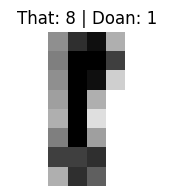

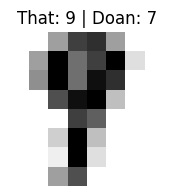

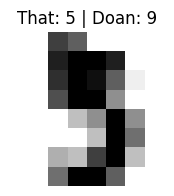

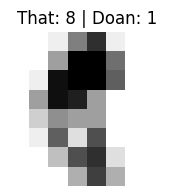

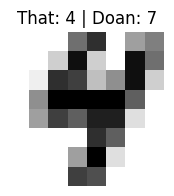

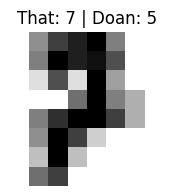

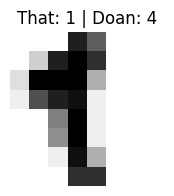

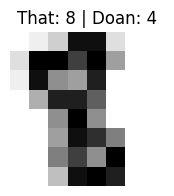

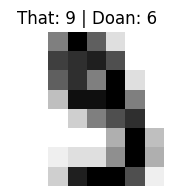

Đã lưu 9 ảnh vào thư mục: anh_du_doan_sai


In [5]:
#câu 5:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(y)), test_size=0.25, random_state=42, stratify=y
)

model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"Accuracy test: {accuracy_score(y_test, y_pred):.4f}")
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
cm_df = pd.DataFrame(cm,
    index=[f"Thật {i}" for i in range(10)],
    columns=[f"Đoán {i}" for i in range(10)])
display(cm_df)
# Liệt kê các cặp nhầm lẫn (chỉ lấy ô ngoài đường chéo có số lượng > 0)
errors_by_pair = []
for true_digit in range(10):
    for predicted_digit in range(10):
        if true_digit != predicted_digit and cm[true_digit, predicted_digit] > 0:
            errors_by_pair.append((true_digit, predicted_digit,
                                   int(cm[true_digit, predicted_digit])))
errors_by_pair.sort(key=lambda x: x[2], reverse=True)
print("Các cặp nhầm lẫn (chữ số thật -> chữ số đoán, số lần):")
for item in errors_by_pair:
    print(item)
 # Vẽ và lưu tối đa 30 ảnh bị đoán sai; tên file ghi nhãn thật và nhãn dự đoán
save_dir = "anh_du_doan_sai"
os.makedirs(save_dir, exist_ok=True)
wrong_positions = np.where(y_pred != y_test)[0]

print("Tổng số ảnh dự đoán sai:", len(wrong_positions))
for order, i in enumerate(wrong_positions[:30], start=1):
    plt.figure(figsize=(2, 2))
    plt.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    plt.title(f"That: {y_test[i]} | Doan: {y_pred[i]}")
    plt.axis("off")
    filename = f"{save_dir}/sai_{order:02d}_that_{y_test[i]}_doan_{y_pred[i]}.png"
    plt.savefig(filename, bbox_inches="tight")
    plt.show()
    plt.close()

print(f"Đã lưu {min(30, len(wrong_positions))} ảnh vào thư mục: {save_dir}")

Nhận xét
Đọc confusion matrix theo từng hàng: phần tử đường chéo là dự đoán đúng; phần tử ngoài đường chéo cho biết chữ số thật bị đoán thành chữ số nào. Các cặp có số lượng lớn nhất được in ở ô trước.

Khi xem ảnh sai, một số chữ số có thể bị nhầm vì nét viết tay gần giống nhau, nét quá mảnh/đậm, hình dạng không cân đối hoặc ảnh có độ phân giải thấp (chỉ 8×8). SVM chỉ học từ các đặc trưng pixel nên các chữ số có hình dáng tương tự dễ gây nhầm lẫn.

In [6]:
import time
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings("ignore", category=ConvergenceWarning)

sample_sizes = [2000, 5000, 10000, 20000]
rows = []

for n in sample_sizes:
    X, y = make_classification(n_samples=n, n_features=20, random_state=0)

    # Chuẩn hóa được đặt trong pipeline để mỗi mô hình tự fit scaler trên dữ liệu train
    models = {
        "SVC": make_pipeline(StandardScaler(), SVC()),
        "LinearSVC": make_pipeline(StandardScaler(), LinearSVC(random_state=0, max_iter=10000))
    }

    for name, model in models.items():
        start = time.perf_counter()
        model.fit(X, y)
        elapsed = time.perf_counter() - start
        rows.append({"n_samples": n, "Mô hình": name,
                     "Thời gian fit (giây)": elapsed})

timing_df = pd.DataFrame(rows)
display(timing_df)
# Tính hệ số tăng thời gian giữa hai cỡ dữ liệu liên tiếp
wide = timing_df.pivot(index="n_samples", columns="Mô hình",
                       values="Thời gian fit (giây)")
ratios = wide / wide.shift(1)
print("Thời gian fit theo từng cỡ dữ liệu (giây):")
display(wide)
print("Hệ số thời gian so với cỡ dữ liệu liền trước:")
display(ratios)

,n_samples,Mô hình,Thời gian fit (giây)
0,2000,SVC,0.035624
1,2000,LinearSVC,0.005432
2,5000,SVC,0.094382
3,5000,LinearSVC,0.004120
4,10000,SVC,1.091648
5,10000,LinearSVC,0.007863
6,20000,SVC,3.175187
7,20000,LinearSVC,0.015152


Thời gian fit theo từng cỡ dữ liệu (giây):


Mô hình,LinearSVC,SVC
n_samples,,
2000,0.005432,0.035624
5000,0.004120,0.094382
10000,0.007863,1.091648
20000,0.015152,3.175187


Hệ số thời gian so với cỡ dữ liệu liền trước:


Mô hình,LinearSVC,SVC
n_samples,,
2000,NaN,NaN
5000,0.758409,2.649362
10000,1.908684,11.566290
20000,1.926850,2.908617


Nhận xét
SVC với kernel mặc định RBF phải xử lý quan hệ phi tuyến giữa các điểm; chi phí huấn luyện thường tăng nhanh khi số mẫu lớn. LinearSVC tối ưu cho ranh giới tuyến tính và thường phù hợp hơn với dữ liệu nhiều mẫu, nên thường có thời gian huấn luyện thấp hơn đáng kể.

Hệ số tăng thời gian được tính bằng thời gian ở cỡ dữ liệu hiện tại chia cho thời gian ở cỡ liền trước. Không nên kỳ vọng cứ tăng gấp đôi số mẫu thì thời gian luôn tăng đúng một hệ số cố định: kết quả phụ thuộc thuật toán tối ưu, dữ liệu, CPU, bộ nhớ và phiên bản thư viện. Đề bài yêu cầu so sánh tương đối trên cùng một máy.